# Hirakud Reservoir – CWC data cleaning (2010–2025)
Steps: load → profile → validate → drop useless columns → fix types → handle missing/duplicates/outliers → export.

**Column decisions**
| Column | Decision | Why |
|---|---|---|
| `Date` | keep | time index |
| `Lat`, `Long` | keep | needed for the Open-Meteo API |
| `Storage`, `Level` | keep | the actual measurements (targets/features) |
| `Full_reservoir_level`, `Live_capacity_FRL` | used to validate + derive `pct_full`, then dropped | constant for the whole dataset |
| `Reservoir_name`, `Basin`, `Agency_name` | dropped | single constant value |
| `subbasin` | dropped | 100% missing |
| `Year`, `Month` | dropped | redundant, derivable from `Date` |

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW_DIR = Path("../data/cwc")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and combine yearly files (raw files are never modified)

In [13]:
frames = []
for f in sorted(RAW_DIR.glob("*.csv")):
    d = pd.read_csv(f, na_values=["NA", "N/A", "", "-"], skipinitialspace=True)
    d.columns = d.columns.str.strip()
    d["source_file"] = f.name
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
print(raw.shape)
raw.head()

(5646, 14)


,Reservoir_name,Basin,subbasin,Agency_name,Lat,Long,Date,Year,Month,Full_reservoir_level,Live_capacity_FRL,Storage,Level,source_file
0,Hirakud Reservoir,Mahanadi Basin,NaN,CWC,21.633833,83.80547,2010-03-03,2010,3,192.02,5.378,3.403,188.53,cwc-2010.csv
1,Hirakud Reservoir,Mahanadi Basin,NaN,CWC,21.633833,83.80547,2010-03-06,2010,3,192.02,5.378,3.303,188.40,cwc-2010.csv
2,Hirakud Reservoir,Mahanadi Basin,NaN,CWC,21.633833,83.80547,2010-03-07,2010,3,192.02,5.378,3.286,188.35,cwc-2010.csv
3,Hirakud Reservoir,Mahanadi Basin,NaN,CWC,21.633833,83.80547,2010-03-14,2010,3,192.02,5.378,3.075,187.94,cwc-2010.csv
4,Hirakud Reservoir,Mahanadi Basin,NaN,CWC,21.633833,83.80547,2010-03-16,2010,3,192.02,5.378,3.003,187.81,cwc-2010.csv


## 2. Profile

In [14]:
raw.info()
display(raw.isna().mean().mul(100).round(1).rename("% missing").to_frame())
display(raw.nunique().rename("n_unique").to_frame())
display(raw.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 5646 entries, 0 to 5645
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Reservoir_name        5646 non-null   str    
 1   Basin                 5646 non-null   str    
 2   subbasin              0 non-null      float64
 3   Agency_name           5646 non-null   str    
 4   Lat                   5645 non-null   float64
 5   Long                  5645 non-null   float64
 6   Date                  5646 non-null   str    
 7   Year                  5646 non-null   int64  
 8   Month                 5646 non-null   int64  
 9   Full_reservoir_level  5646 non-null   float64
 10  Live_capacity_FRL     5646 non-null   float64
 11  Storage               4006 non-null   float64
 12  Level                 4006 non-null   float64
 13  source_file           5646 non-null   str    
dtypes: float64(7), int64(2), str(5)
memory usage: 617.7 KB


,% missing
Reservoir_name,0.0
Basin,0.0
subbasin,100.0
Agency_name,0.0
Lat,0.0
Long,0.0
Date,0.0
Year,0.0
Month,0.0
Full_reservoir_level,0.0


,n_unique
Reservoir_name,1
Basin,1
subbasin,0
Agency_name,1
Lat,1
Long,1
Date,5646
Year,16
Month,12
Full_reservoir_level,1


,count,mean,std,min,25%,50%,75%,max
subbasin,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lat,5645.0,21.633833,3.553028e-15,21.633833,21.633833,21.633833,21.633833,21.633833
Long,5645.0,83.805470,1.421211e-14,83.805470,83.805470,83.805470,83.805470,83.805470
Year,5646.0,2017.240170,4.471548e+00,2010.000000,2013.000000,2017.000000,2021.000000,2025.000000
Month,5646.0,6.436592,3.439231e+00,1.000000,3.000000,6.000000,9.000000,12.000000
Full_reservoir_level,5646.0,192.020000,2.842423e-14,192.020000,192.020000,192.020000,192.020000,192.020000
Live_capacity_FRL,5646.0,5.378000,0.000000e+00,5.378000,5.378000,5.378000,5.378000,5.378000
Storage,4006.0,3.045532,1.491821e+00,0.233000,1.694405,3.245000,4.386000,5.378000
Level,4006.0,188.292570,3.171188e+00,180.940000,185.720000,189.105000,191.130000,192.160000


## 3. Drop columns with no information

In [15]:
const_cols = [c for c in raw.columns if raw[c].nunique(dropna=True) <= 1 and c not in ("Lat", "Long")]
print("Constant / empty columns:", const_cols)

# Constants we still want for validation before dropping
FRL = raw["Full_reservoir_level"].dropna().iloc[0]
CAPACITY = raw["Live_capacity_FRL"].dropna().iloc[0]
print(f"FRL = {FRL} m, live capacity at FRL = {CAPACITY} BCM")

df = raw.drop(columns=const_cols + ["Year", "Month", "source_file"], errors="ignore").copy()
df = df.rename(columns={"Date": "date", "Lat": "lat", "Long": "lon", "Storage": "storage_bcm", "Level": "level_m"})
df = df[["date", "lat", "lon", "storage_bcm", "level_m"]]
df.head()

Constant / empty columns: ['Reservoir_name', 'Basin', 'subbasin', 'Agency_name', 'Full_reservoir_level', 'Live_capacity_FRL']
FRL = 192.02 m, live capacity at FRL = 5.378 BCM


,date,lat,lon,storage_bcm,level_m
0,2010-03-03,21.633833,83.80547,3.403,188.53
1,2010-03-06,21.633833,83.80547,3.303,188.40
2,2010-03-07,21.633833,83.80547,3.286,188.35
3,2010-03-14,21.633833,83.80547,3.075,187.94
4,2010-03-16,21.633833,83.80547,3.003,187.81


## 4. Fix types, standardise, sort

In [16]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for c in ["lat", "lon", "storage_bcm", "level_m"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

assert df["date"].notna().all(), "Unparseable dates found"
df = df.sort_values("date").reset_index(drop=True)
df.dtypes

date           datetime64[us]
lat                   float64
lon                   float64
storage_bcm           float64
level_m               float64
dtype: object

## 5. Duplicates

In [17]:
print("Exact duplicates:", df.duplicated().sum())
print("Duplicate dates :", df["date"].duplicated().sum())
df = df.drop_duplicates()
# if one date still appears twice, keep the row with the most information
df = (df.assign(_n=df.notna().sum(axis=1))
        .sort_values(["date", "_n"]).drop_duplicates("date", keep="last")
        .drop(columns="_n").reset_index(drop=True))

Exact duplicates: 0
Duplicate dates : 0


## 6. Lat/Long
Coordinates are a single fixed point, so a missing value is safely filled with the known one (not a statistical imputation).

In [18]:
print("Unique coords:", df[["lat", "lon"]].drop_duplicates().dropna().shape[0])
df["lat"] = df["lat"].fillna(df["lat"].mode()[0])
df["lon"] = df["lon"].fillna(df["lon"].mode()[0])
assert df[["lat", "lon"]].drop_duplicates().shape[0] == 1

Unique coords: 1


## 7. Missing measurements
Storage/Level are the actual signal. Rows with **neither** value are useless for modelling, so they are removed.
We deliberately do **not** impute the remaining gaps here – interpolating a target before the train/test split would leak information.

In [19]:
print("Rows total:", len(df))
print("Rows with no storage AND no level:", df[["storage_bcm", "level_m"]].isna().all(axis=1).sum())
print("Rows with only one of the two     :", (df[["storage_bcm", "level_m"]].isna().sum(axis=1) == 1).sum())
print("Observations per year:"); display(df.dropna(subset=["storage_bcm", "level_m"], how="all").groupby(df["date"].dt.year).size())

all_days = pd.date_range(df.date.min(), df.date.max())
print("Calendar days absent from the files:", len(all_days.difference(df.date)))

df = df.dropna(subset=["storage_bcm", "level_m"], how="all").reset_index(drop=True)

Rows total: 5646
Rows with no storage AND no level: 1640
Rows with only one of the two     : 0
Observations per year:


date
2010    365
2011    365
2012    366
2013    240
2014    289
2015    320
2016    301
2017    356
2018    339
2019    365
2020    311
2021    117
2022    115
2023     75
2024     56
2025     26
dtype: int64

Calendar days absent from the files: 25


## 8. Validation / outliers (domain rules)

In [20]:
bad_level   = df[(df.level_m > FRL + 0.5) | (df.level_m <= 0)]
bad_storage = df[(df.storage_bcm < 0) | (df.storage_bcm > CAPACITY * 1.05)]
print("Level above FRL (real surcharge, kept):", (df.level_m > FRL).sum())
print("Level out of range  :", len(bad_level))
print("Storage out of range:", len(bad_storage))

# Storage and level are physically linked (monotonic) – flag points that break the relationship
both = df.dropna(subset=["storage_bcm", "level_m"])
print("Spearman(storage, level) =", round(both["storage_bcm"].corr(both["level_m"], method="spearman"), 4), "(<1 here is due to the rating-curve change, handled in step 9)")

# Day-to-day jump check using a robust (MAD) rule
d = df.set_index("date")["storage_bcm"].dropna()
jump = d.diff().abs()
thr = jump.median() + 6 * (jump - jump.median()).abs().median()
print("Suspicious jumps:", (jump > thr).sum(), "(threshold %.3f BCM)" % thr)
display(jump[jump > thr].sort_values(ascending=False).head(10))

Level above FRL (real surcharge, kept): 36
Level out of range  : 0
Storage out of range: 0
Spearman(storage, level) = 0.9834 (<1 here is due to the rating-curve change, handled in step 9)
Suspicious jumps: 418 (threshold 0.112 BCM)


date
2012-08-07    1.87800
2023-09-14    1.45055
2014-07-24    1.29760
2021-09-15    1.28404
2012-01-09    1.28100
2022-07-20    1.26183
2011-08-17    1.11600
2022-08-17    1.07434
2016-09-03    1.03869
2012-08-22    1.00100
Name: storage_bcm, dtype: float64

In [21]:
# Remove only physically impossible values; keep real extremes (floods/drawdowns)
df.loc[df.index.isin(bad_level.index), "level_m"] = np.nan
df.loc[df.index.isin(bad_storage.index), "storage_bcm"] = np.nan
df = df.dropna(subset=["storage_bcm", "level_m"], how="all").reset_index(drop=True)

## 9. Storage rating-curve break (important with the 2010+ data)
Level is a direct measurement, storage is read off a level→storage table. The table changed: before **2013-02-01** (and rows that report the legacy 5.378 BCM verbatim at FRL) storage is ~0.5 BCM higher than later at the same level (old capacity table, FRL = 5.378 BCM). Mixing both eras would make `storage_bcm` inconsistent, so storage before the break is re-derived from `level_m` using the current table.

In [22]:
BREAK = pd.Timestamp("2013-02-01")
# Placeholder: in 2013-15, when level hits FRL the legacy capacity (5.378) is reported verbatim
placeholder = np.isclose(df.storage_bcm, CAPACITY)
print("Legacy-capacity placeholders after the break:", (placeholder & (df.date >= BREAK)).sum())
new_era = df[(df.date >= BREAK) & df.storage_bcm.notna() & ~placeholder]

# current level -> storage curve: median storage per 0.05 m level bin, forced monotone
curve = (new_era.assign(lb=(new_era.level_m / 0.05).round() * 0.05)
                .groupby("lb").storage_bcm.median().cummax())
def level_to_storage(level):
    return np.interp(level, curve.index.values, curve.values)

old = (df.date < BREAK) | placeholder
resid_old = (df.loc[old, "storage_bcm"] - level_to_storage(df.loc[old, "level_m"]))
print(f"Old-era mean offset: {resid_old.mean():.3f} BCM (max {resid_old.max():.3f})")
resid_new = (df.loc[~old, "storage_bcm"] - level_to_storage(df.loc[~old, "level_m"]))
print(f"New-era mean abs residual: {resid_new.abs().mean():.3f} BCM  <- should be tiny")

df["storage_source"] = np.where(old, "derived_from_level", "reported")
df.loc[old, "storage_bcm"] = level_to_storage(df.loc[old, "level_m"]).round(5)
df["storage_source"] = df["storage_source"].astype("category")

Legacy-capacity placeholders after the break: 20
Old-era mean offset: 0.467 BCM (max 0.875)
New-era mean abs residual: 0.006 BCM  <- should be tiny


## 10. Stale (repeated) readings and derived features

In [23]:
# Identical storage+level on consecutive days = probably a carried-forward value, flagged (not removed)
same = (df[["storage_bcm", "level_m"]].diff().abs().sum(axis=1) == 0)
df["stale_value"] = same & (df["date"].diff().dt.days <= 1)
print("Stale readings:", df["stale_value"].sum(), f"({df['stale_value'].mean():.1%})")

# pct_full relative to the *current* capacity table (storage at FRL), not the legacy 5.378 BCM
CAP_NOW = float(level_to_storage(FRL))
print(f"Current live storage at FRL: {CAP_NOW:.3f} BCM (legacy: {CAPACITY} BCM)")
df["pct_full"] = (df["storage_bcm"] / CAP_NOW * 100).clip(upper=110).round(2)
df.describe().T

Stale readings: 1040 (26.0%)
Current live storage at FRL: 4.827 BCM (legacy: 5.378 BCM)


,count,mean,min,25%,50%,75%,max,std
date,4006,2016-03-04 21:39:05.481777,2010-01-01 00:00:00,2012-09-28 06:00:00,2016-03-19 12:00:00,2019-03-04 18:00:00,2025-07-10 00:00:00,NaN
lat,4006.0,21.633833,21.633833,21.633833,21.633833,21.633833,21.633833,0.0
lon,4006.0,83.80547,83.80547,83.80547,83.80547,83.80547,83.80547,0.0
storage_bcm,4006.0,2.911838,0.233,1.59501,3.08111,4.25174,4.9067,1.428076
level_m,4006.0,188.29257,180.94,185.72,189.105,191.13,192.16,3.171188
pct_full,4006.0,60.322264,4.83,33.04,63.825,88.08,101.65,29.58432


## 11. Visual check

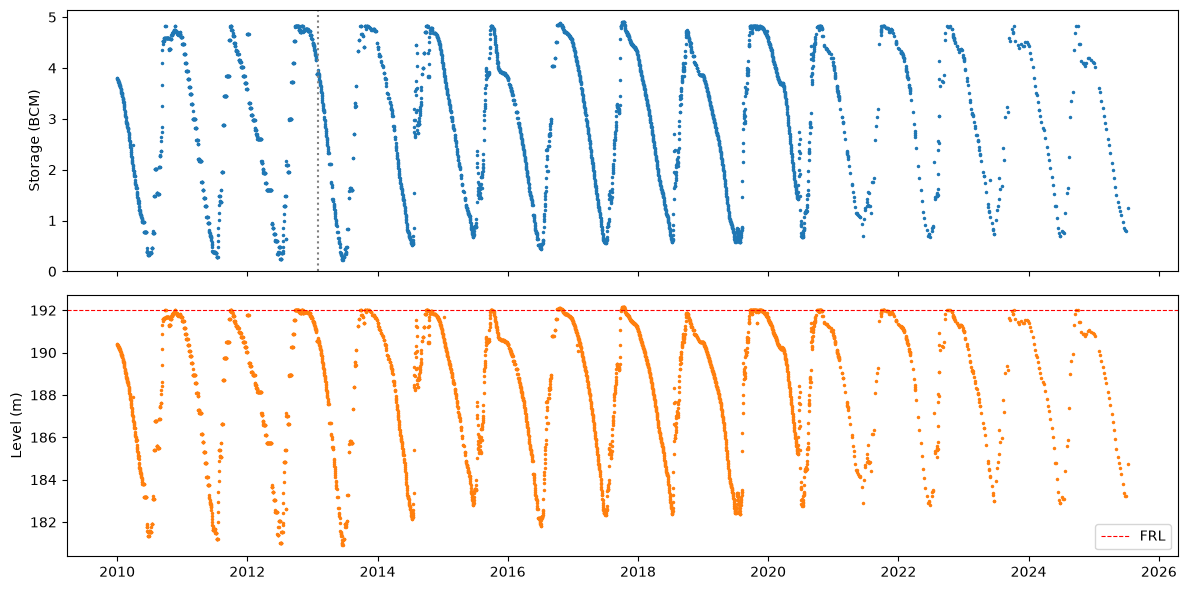

In [24]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(df["date"], df["storage_bcm"], ".", ms=3); ax[0].set_ylabel("Storage (BCM)")
ax[1].plot(df["date"], df["level_m"], ".", ms=3, color="tab:orange"); ax[1].set_ylabel("Level (m)")
ax[1].axhline(FRL, ls="--", c="r", lw=.8, label="FRL"); ax[0].axvline(BREAK, c="gray", ls=":"); ax[1].legend()
plt.tight_layout(); plt.show()

## 12. Final checks and export

In [25]:
assert df["date"].is_unique and df["date"].is_monotonic_increasing
assert df[["lat", "lon"]].notna().all().all()
print(df.shape, df["date"].min().date(), "->", df["date"].max().date())

df.to_csv(OUT_DIR / "hirakud_clean.csv", index=False)
df.head()

(4006, 8) 2010-01-01 -> 2025-07-10


,date,lat,lon,storage_bcm,level_m,storage_source,stale_value,pct_full
0,2010-01-01,21.633833,83.80547,3.80251,190.41,derived_from_level,False,78.77
1,2010-01-02,21.633833,83.80547,3.79659,190.40,derived_from_level,False,78.65
2,2010-01-03,21.633833,83.80547,3.78623,190.38,derived_from_level,False,78.44
3,2010-01-04,21.633833,83.80547,3.77069,190.35,derived_from_level,False,78.11
4,2010-01-05,21.633833,83.80547,3.76181,190.33,derived_from_level,False,77.93
